# 🧪 TP - Régression Linéaire sur données automobiles

## 🎯 Objectif du TP

Ce TP a pour but de vous familiariser avec la régression linéaire en utilisant un dataset réel sur les prix des voitures. Vous appliquerez les différentes étapes d'un projet de data science :
- Prétraitement des données
- Analyse exploratoire des données (EDA)
- Analyse des colinéarités entre variables (VIF)
- Modélisation avec différentes approches
- Evaluation et optimisation des modèles

**Durée estimée :** 2 heures

**Dataset :** Carseats

#### Lien de la documentation : https://islp.readthedocs.io/en/latest/datasets/Carseats.html

In [1]:
# Étape 1 : Importer les bibliothèques essentielles pour l'analyse de données
# - numpy pour les calculs numériques
# - pandas pour la manipulation des données
# - matplotlib et seaborn pour la visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Étape 2 : Configurer l'affichage des données pour une meilleure lisibilité
# - Afficher toutes les colonnes d'un DataFrame
# - Définir un style de graphique propre et professionnel
# - Choisir une palette de couleurs adaptée
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('coolwarm')

# Étape 3 : Activer l'affichage interactif des graphiques dans le notebook
# Cette commande permet d'afficher les graphiques directement dans le notebook
%matplotlib inline

# Étape 4 : Gérer les avertissements pour un environnement de travail plus propre
# Cette commande masque les avertissements non critiques pour ne pas perturber l'affichage
import warnings
warnings.filterwarnings('ignore')

## Chargement du dataset

Nous allons utiliser un dataset sur les prix de voitures.

In [4]:
# Étape 1 : Importer le module os pour gérer les opérations sur les fichiers
import os

# Étape 2 : Définir l'URL du dataset à télécharger
url = "https://raw.githubusercontent.com/JWarmenhoven/ISLR-python/master/Notebooks/Data/Carseats.csv"

# Étape 3 : Essayer de charger le dataset depuis un fichier local
try:
    # Tenter de lire le fichier local d'abord
    df = pd.read_csv('cardata.csv')
    print("Dataset chargé depuis le fichier local.")
    
# Étape 4 : Si le fichier local n'existe pas, le télécharger depuis l'URL
except FileNotFoundError:
    # Si le fichier n'existe pas, le télécharger
    print("Téléchargement du dataset...")
    df = pd.read_csv(url)
    # Sauvegarder le dataset téléchargé localement pour une utilisation future
    df.to_csv('cardata.csv', index=False)
    print("Dataset téléchargé et sauvegardé localement.")

# Étape 5 : Afficher un aperçu des premières lignes du dataset
# Cela permet de vérifier que le chargement s'est bien déroulé
df.head()

Dataset chargé depuis le fichier local.


,Unnamed: 0,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,1,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,2,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,3,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,4,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,5,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [ ]:
# Étape 1 : Afficher les dimensions du dataset (nombre de lignes et colonnes)
# Cela permet de comprendre la taille des données avec lesquelles on travaille


# Étape 2 : Afficher les types de données de chaque colonne
# Important pour vérifier que les types sont corrects (numériques, catégoriels, etc.)


# Étape 3 : Afficher les statistiques descriptives du dataset
# Donne un aperçu rapide des distributions et valeurs clés (moyenne, écart-type, etc.)


## 1. 🔄 Prétraitement des données

Dans cette section, nous allons :
- Identifier les colonnes inutiles ou redondantes
- Gérer les données manquantes
- Normaliser ou standardiser les colonnes numériques

### 1.1 Vérification des données manquantes

In [5]:
#  Afficher le nombre de valeurs manquantes par colonne
# Cela permet d'identifier quelles colonnes contiennent des données manquantes



### 1.2 Séparation des variables catégorielles et numériques

In [14]:
# Étape 1 : Identifier les colonnes numériques
# On utilise select_dtypes() pour filtrer les colonnes de type int64 et float64
# Ces types correspondent aux variables numériques continues ou discrètes
#Assigner les colonnes numériques à une variable numeric_cols
numeric_cols = 

# Étape 2 : Identifier les colonnes catégorielles  
# On utilise select_dtypes() pour filtrer les colonnes de type object et category
# Ces types correspondent aux variables qualitatives (texte, catégories)
#Assigner les colonnes catégorielles à une variable categorical_cols
categorical_cols = 

# Étape 3 : Afficher les résultats
# On affiche les listes des colonnes numériques et catégorielles
# Cela permet de vérifier que la séparation s'est bien passée
#Afficher les variables numériques et catégorielles
print("Variables numériques:", numeric_cols)
print("Variables catégorielles:", categorical_cols)

Variables numériques: ['Unnamed: 0', 'Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education']
Variables catégorielles: ['ShelveLoc', 'Urban', 'US']


In [10]:
#Vérification des types de variables:


Unnamed: 0       int64
Sales          float64
CompPrice        int64
Income           int64
Advertising      int64
Population       int64
Price            int64
ShelveLoc       object
Age              int64
Education        int64
Urban           object
US              object
dtype: object


In [12]:
#Afficher le dataframe pour encore vérifier les types de variables


,Unnamed: 0,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,1,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,2,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,3,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,4,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,5,4.15,141,64,3,340,128,Bad,38,13,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...
395,396,12.57,138,108,17,203,128,Good,33,14,Yes,Yes
396,397,6.14,139,23,3,37,120,Medium,55,11,No,Yes
397,398,7.41,162,26,12,368,159,Medium,40,18,Yes,Yes
398,399,5.94,100,79,7,284,95,Bad,50,12,Yes,Yes


### 1.3 Transformation des variables catégorielles

In [ ]:
# Étape 1 : Inspection des variables catégorielles
# On parcourt chaque colonne catégorielle pour afficher ses valeurs uniques
# Cela permet de comprendre la nature des données et de vérifier s'il y a des valeurs aberrantes
# Calculer la somme des valeurs unique de chaque colonne du categorical_cols



# Étape 2 : Encodage One-Hot des variables catégorielles
# On utilise la fonction get_dummies pour transformer les variables catégorielles en variables binaires
# - columns=categorical_cols : spécifie les colonnes à encoder
# - drop_first=True : supprime la première catégorie pour éviter la colinéarité
# Cela permet de convertir les catégories en variables numériques que les modèles peuvent comprendre
df_encoded = 


# Étape 3 : Vérification du résultat
# On affiche les premières lignes du dataframe encodé pour s'assurer que la transformation s'est bien passée
df_encoded.head()

### 1.4 Séparation des données en ensembles d'entraînement et de test

> ⭐ Pensez à faire le `train_test_split` **avant** toute opération de scaling !

In [ ]:
# Importation de la fonction train_test_split pour séparer les données
from sklearn.model_selection import train_test_split

# Étape 1: Préparation des données
# - X contient toutes les features (variables explicatives) sauf 'Sales'
# - y contient la variable cible 'Sales' que nous voulons prédire
X = 
y = 

# Étape 2: Séparation des données
# - On divise les données en ensembles d'entraînement (80%) et de test (20%)
# - random_state=42 assure la reproductibilité des résultats
# Dabs l'ordres nous aurons X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = 

# Étape 3: Vérification des dimensions avant séparation
# Utilisation de la méthode shape 
print(f"Dimensions de X: {X.shape}")
print(f"Dimensions de y: {y.shape}")

# Étape 4: Vérification des dimensions
# - Afficher la taille de chaque ensemble pour s'assurer que la séparation est correcte
print(f"Dimensions de X_train: {X_train.shape}")
print(f"Dimensions de X_test: {X_test.shape}")
print(f"Dimensions de y_train: {y_train.shape}")
print(f"Dimensions de y_test: {y_test.shape}")

### 1.5 Normalisation des variables numériques

Nous utiliserons RobustScaler qui est plus résistant aux outliers.

In [ ]:
# Étape 1: Importer la classe RobustScaler pour la normalisation
from sklearn.preprocessing import RobustScaler

# Étape 2: Identifier les colonnes numériques à normaliser
# On sélectionne uniquement les colonnes de type int64 et float64 attention exclue les données catégorielles
num_cols =
num_cols
# Étape 3: Initialiser et appliquer le scaler sur les données d'entraînement
# - On crée une copie des données pour ne pas modifier l'original
# - On applique fit_transform qui calcule les paramètres et transforme les données
scaler = 
X_train_scaled = 
X_train_scaled[num_cols] = 

# Étape 4: Appliquer la même transformation sur les données de test
# Important: on utilise transform() et non fit_transform() pour appliquer les mêmes paramètres
X_test_scaled = 
X_test_scaled[num_cols] = 

# Étape 5: Vérifier le résultat de la normalisation
# On affiche les premières lignes des données normalisées pour vérification
X_train_scaled.head()

,Unnamed: 0,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Good,ShelveLoc_Medium,Urban_Yes,US_Yes
3,-1.036176,-0.368421,0.64,-0.083333,0.728346,-0.644628,0.000000,0.00,0,1,1,1
18,-0.958656,-0.736842,0.84,-0.416667,0.500000,-1.603306,-0.333333,0.75,1,0,0,1
202,-0.007752,-0.157895,0.20,-0.083333,0.519685,0.446281,-0.333333,-1.00,0,0,0,1
250,0.240310,0.684211,0.74,0.416667,0.606299,1.305785,0.629630,0.00,1,0,1,1
274,0.364341,0.578947,0.50,-0.250000,-0.842520,0.082645,-0.777778,-0.75,0,1,1,1


## 2. 📊 Analyse exploratoire des données (EDA)

Étudions les relations entre nos variables et la variable cible pour mieux comprendre le dataset.

In [ ]:
# Étape 1: Créer une figure de taille 15x10 pouces pour contenir tous les histogrammes
plt.figure(figsize=(15, 10))

# Étape 2: Générer les histogrammes pour toutes les colonnes numériques
# - bins=20 : divise les données en 20 intervalles
# - figsize=(15,10) : taille de la figure (redondant avec plt.figure)


# Étape 3: Ajouter un titre principal au graphique
# - y=1.02 : position verticale du titre
# - fontsize=16 : taille de la police

# Étape 4: Ajuster l'espacement entre les sous-graphiques pour éviter les chevauchements

# Étape 5: Afficher le graphique


In [ ]:
# Boxplot de sales

# Étape 1: Créer une figure de taille 8x6 pouces pour le boxplot
plt.figure(figsize=(8, 6))

# Étape 2: Générer un boxplot de la variable cible 'Sales'
# - y=df['Sales'] : spécifie la variable à visualiser
# - sns.boxplot() : utilise seaborn pour créer le boxplot


# Étape 3: Ajouter un titre descriptif au graphique


# Étape 4: Afficher le graphique
plt.show()

In [ ]:
#Mise en place d'un pairplot

# Étape 1: Sélection des variables à analyser
# On choisit les variables continues les plus pertinentes pour étudier leurs relations
# avec la variable cible 'Sales'. On évite d'inclure trop de variables pour garder
# le graphique lisible et interprétable.
plot_cols = []

# Étape 2: Création du pairplot
# - df[plot_cols] : on sélectionne uniquement les colonnes choisies
# - height=2 : on définit la taille de chaque sous-graphique
# Le pairplot affiche :
# - Des scatter plots pour les relations entre variables
# - Des histogrammes pour la distribution de chaque variable
# Afficher aussi les variables catégorielles



# Étape 3: Ajout d'un titre principal
# - y=1.02 : position verticale du titre pour éviter les chevauchements
# Le titre doit être descriptif et expliquer ce que montre le graphique




# Étape 4: Affichage du graphique
# Cette commande est nécessaire pour visualiser le pairplot
plt.show()

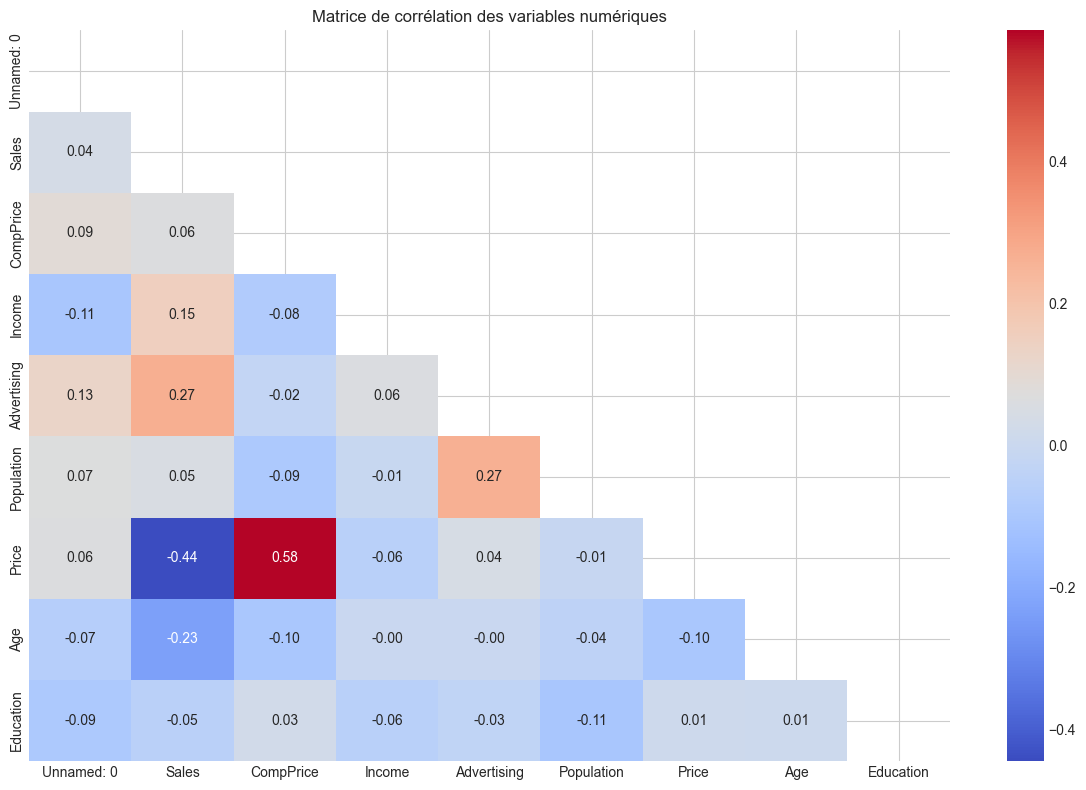

In [52]:
#Matrice de corrélation

# Étape 1: Créer une figure de taille 12x8 pouces pour la heatmap
# - figsize=(12,8) : définit la taille de la figure pour une meilleure lisibilité
plt.figure(figsize=(12, 8))

# Étape 2: Calculer la matrice de corrélation
# - df[numeric_cols] : sélectionne uniquement les colonnes numériques
# - .corr() : calcule les coefficients de corrélation entre les variables
correlation_matrix = 

# Étape 3: Créer un masque triangulaire supérieur
# - np.triu() : génère un masque pour cacher la partie supérieure de la matrice
# Cela évite la redondance car la matrice de corrélation est symétrique
mask = 

# Étape 4: Générer la heatmap avec seaborn
# - correlation_matrix : la matrice à visualiser
# - annot=True : affiche les valeurs de corrélation dans chaque case
# - fmt='.2f' : formate les valeurs à 2 décimales
# - cmap='coolwarm' : utilise une palette de couleurs intuitive
# - mask=mask : applique le masque triangulaire

# Étape 5: Ajouter un titre descriptif au graphique
plt.title('Matrice de corrélation des variables numériques')

# Étape 6: Ajuster l'espacement pour éviter les chevauchements
plt.tight_layout()

# Étape 7: Afficher le graphique
plt.show()

### 2.1 Questions exploratoires

**Questions à répondre :**
1. Quelles variables semblent les plus corrélées à la variable cible (Sales) ?
2. Quelles variables pourraient être redondantes (fortement corrélées entre elles) ?

**Réponses :**

1. D'après la matrice de corrélation et les pairplots, les variables les plus corrélées aux ventes (Sales) semblent être:
   - Price (corrélation négative) : plus le prix augmente, plus les ventes diminuent
   - Advertising (corrélation positive) : plus la publicité augmente, plus les ventes augmentent
   - ShelveLoc (visualisé dans les pairplots) : l'emplacement en rayon semble avoir un impact sur les ventes

2. Le boxplot montre quelques outliers dans les ventes (Sales), notamment des valeurs élevées. Ces points pourraient représenter des magasins particulièrement performants ou des conditions de marché spécifiques.

3. Nous avons price et comprice, et possiblement advertising et population mais une anaylise du vif nous permettras de savoir ce que nous devons faire avec ses variables

## 3. 🔢 Analyse du VIF (Variance Inflation Factor)

Le VIF quantifie la multicolinéarité entre les variables explicatives. Un VIF élevé (>5 ou >10) indique qu'une variable est fortement corrélée avec d'autres variables.

## 📐 Qu'est-ce que le VIF (Variance Inflation Factor) ?

Le **VIF** est un indicateur utilisé pour **mesurer la multicolinéarité** entre les variables explicatives d’un modèle de régression linéaire.

### 🧠 Intuition

- Une variable a un **VIF élevé** si elle est **fortement corrélée à une ou plusieurs autres variables**.
- Cela pose un problème car le modèle peut avoir des **coefficients instables**, difficilement interprétables.


### 📏 Formule

Pour une variable $X_j$ :

$$
\text{VIF}(X_j) = \frac{1}{1 - R_j^2}
$$

Où :
- $R_j^2$ est le **coefficient de détermination** obtenu en régressant $X_j$ sur toutes les autres variables.
- Plus $R_j^2$ est proche de 1, plus le VIF est élevé (donc plus la variable est prédite par les autres → colinéarité !).


### 📊 Interprétation des valeurs

| VIF         | Interprétation                                      |
|-------------|-----------------------------------------------------|
| 1           | Aucune colinéarité                                  |
| 1 < VIF < 5 | Colinéarité modérée, généralement acceptable        |
| 5 < VIF < 10| Colinéarité significative, à surveiller             |
| > 10        | Colinéarité très forte, variable à retirer/réduire  |


📐 Formule mathématique de $R^2$ :

$$
R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}i)^2}{\sum{i=1}^{n} (y_i - \bar{y})^2}
$$



🧠 Explication :
- $y_i$ : la valeur réelle de l’observation $i$
- $\hat{y}_i$ : la valeur prédite par le modèle pour l’observation $i$
- $\bar{y}$ : la moyenne des valeurs observées
- $n$ : le nombre total d’observations

📊 Tableau d'interprétation des valeurs de $R^2$

| Valeur de $R^2$ | Signification                                      |
|-----------------|----------------------------------------------------|
| $R^2 = 1$       | Le modèle explique parfaitement la variance        |
| $R^2 = 0$       | Le modèle est aussi bon que la moyenne             |
| $R^2 < 0$       | Le modèle est pire qu'une prédiction naïve         |


In [ ]:
# 1. Importer les bibliothèques nécessaires
# statsmodels pour les modèles statistiques
# variance_inflation_factor pour calculer le VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 2. Ajouter une constante au modèle
# La constante représente l'intercept (ordonnée à l'origine) dans la régression linéaire
# Nécessaire pour le calcul correct du VIF
X_with_const = sm.add_constant(X_train_scaled)

# 3. Préparer la structure pour stocker les résultats VIF
# Créer un DataFrame vide qui contiendra les noms des variables et leurs VIF
vif_data = pd.DataFrame()

# 4. Remplir le DataFrame avec les noms des variables
# On récupère les noms des colonnes de notre dataset avec constante
vif_data['Variable'] = X_with_const.columns

# 5. Calculer le VIF pour chaque variable
# On utilise une compréhension de liste pour itérer sur chaque variable
# variance_inflation_factor prend en paramètre les valeurs du dataset et l'index de la variable
vif_data['VIF'] = [variance_inflation_factor(X_with_const.values, i) for i in range(X_with_const.shape[1])]

# 6. Afficher les résultats triés par VIF décroissant
# Cela permet de voir rapidement les variables les plus problématiques
print(vif_data.sort_values(by='VIF', ascending=False))

### 3.1 Identification et suppression des variables à forte multicolinéarité

En se basant sur les VIF, nous allons progressivement supprimer les variables les plus problématiques (VIF > 5 ou 10).

In [ ]:
# Étape 1 : Identifier les variables avec VIF élevé
# On commence par la constante qui a toujours un VIF élevé
high_vif_vars = ['const']

# Étape 2 : Ajouter d'autres variables problématiques
# Vérifiez si la colonne 'Unnamed: 0' existe et si c'est juste un index sans signification
if 'Unnamed: 0' in X_train_scaled.columns:
    high_vif_vars.append('Unnamed: 0')

# Étape 3 : Créer de nouveaux jeux de données sans ces variables
# On utilise drop() pour supprimer les colonnes problématiques des données d'entraînement et de test
X_train_filtered = X_train_scaled.drop(columns=[col for col in high_vif_vars if col in X_train_scaled.columns])
X_test_filtered = X_test_scaled.drop(columns=[col for col in high_vif_vars if col in X_test_scaled.columns])

# Étape 4 : Recalculer les VIF sur les données filtrées
# On ajoute d'abord une constante au nouveau jeu de données
X_filtered_with_const = sm.add_constant(X_train_filtered)

# Étape 5 : Préparer un DataFrame pour stocker les nouveaux VIF
vif_data_filtered = pd.DataFrame()
vif_data_filtered['Variable'] = X_filtered_with_const.columns

# Étape 6 : Calculer les nouveaux VIF pour chaque variable
vif_data_filtered['VIF'] = [variance_inflation_factor(X_filtered_with_const.values, i) 
                           for i in range(X_filtered_with_const.shape[1])]

# Étape 7 : Afficher les résultats triés par VIF décroissant
print(vif_data_filtered.sort_values(by='VIF', ascending=False))

### 3.2 Analyse finale des VIF

Après avoir supprimé les variables problématiques, analysons les résultats finaux des VIF pour confirmer l'absence de multicolinéarité excessive entre nos variables restantes.

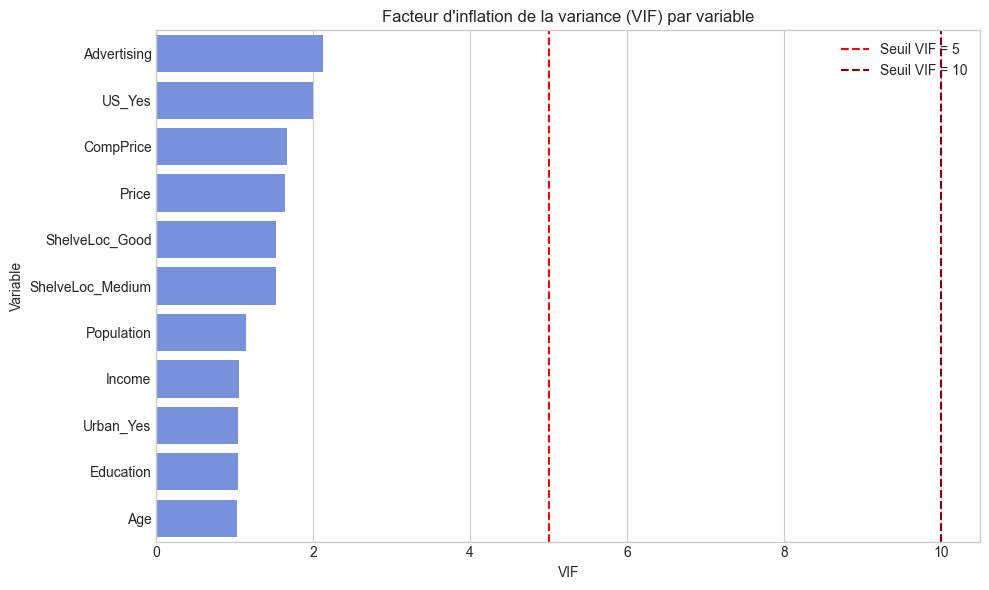

In [59]:
# Visualiser les VIF finaux
plt.figure(figsize=(10, 6))
vif_plot = vif_data_filtered.copy()
vif_plot = vif_plot[vif_plot['Variable'] != 'const']  # Exclure la constante pour une meilleure visualisation
vif_plot = vif_plot.sort_values('VIF', ascending=False)

# Création du graphique à barres
sns.barplot(x='VIF', y='Variable', data=vif_plot)
plt.axvline(x=5, color='r', linestyle='--', label='Seuil VIF = 5')
plt.axvline(x=10, color='darkred', linestyle='--', label='Seuil VIF = 10')
plt.title('Facteur d\'inflation de la variance (VIF) par variable')
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation des VIF :**

- Un VIF > 10 indique une forte multicolinéarité problématique
- Un VIF entre 5 et 10 indique une multicolinéarité modérée à surveiller
- Un VIF < 5 est généralement acceptable pour la modélisation

D'après notre analyse, les variables restantes montrent des niveaux de multicolinéarité acceptables, ce qui nous permet de poursuivre avec la modélisation sans craindre d'instabilité dans les coefficients.

## 4. 📊 Modèle de régression linéaire (OLS)

Nous allons maintenant entraîner un modèle de régression linéaire avec la méthode des moindres carrés ordinaires (OLS).

In [ ]:
# 1. Importer les bibliothèques nécessaires
# - LinearRegression pour créer le modèle de régression linéaire
# - mean_squared_error, r2_score, mean_absolute_error pour évaluer les performances
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 2. Créer et entraîner le modèle de régression linéaire
# - Instancier un objet LinearRegression
# - Entraîner le modèle sur les données d'entraînement filtrées (X_train_filtered) et les labels (y_train)
lr_model =
lr_model.fit(--------------------)

# 3. Faire des prédictions sur les ensembles d'entraînement et de test
# - Utiliser le modèle entraîné pour prédire les valeurs sur les données d'entraînement et de test
y_train_pred = 
y_test_pred = 

# 4. Évaluer les performances du modèle
# - Calculer les métriques d'évaluation (MSE, MAE, R²) pour les ensembles d'entraînement et de test
# - MSE (Mean Squared Error) : erreur quadratique moyenne
# - MAE (Mean Absolute Error) : erreur absolue moyenne 
# - R² (coefficient de détermination) : qualité de la prédiction
train_mse =
test_mse = 
train_r2 =
test_r2 =
train_mae =
test_mae =

# 5. Afficher les résultats d'évaluation
# - Afficher les métriques pour l'ensemble d'entraînement
print(f"Performances sur l'ensemble d'entraînement:\n")
print(f"MSE: {train_mse:.2f}")  # Plus proche de 0 = meilleur
print(f"MAE: {train_mae:.2f}")  # Plus proche de 0 = meilleur
print(f"R²: {train_r2:.2f}\n")  # Plus proche de 1 = meilleur

# - Afficher les métriques pour l'ensemble de test
print(f"Performances sur l'ensemble de test:\n")
print(f"MSE: {test_mse:.2f}")
print(f"MAE: {test_mae:.2f}")
print(f"R²: {test_r2:.2f}")

In [ ]:
# Affichage des coefficients
# utiliser coef_ lié au model 
coef_df = pd.DataFrame({
    'Feature': 
    'Coefficient': 
})

print(f"Intercept: {lr_model.intercept_:.4f}\n")
print("Coefficients:")
print(coef_df.sort_values(by='Coefficient', ascending=False))

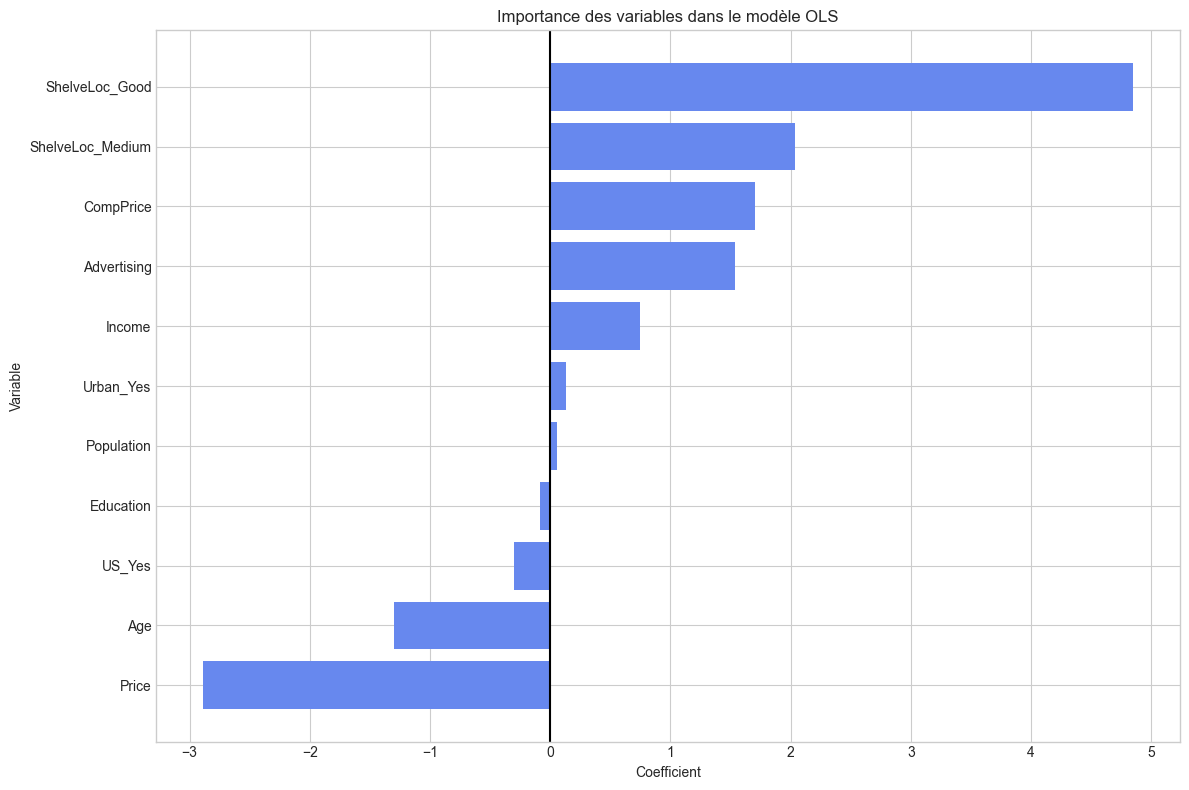

In [67]:
# Visualisation des coefficients sur un graphique
# Afficher les coefficient autour de 0  (utilisation de barh ?  centré en 0 )



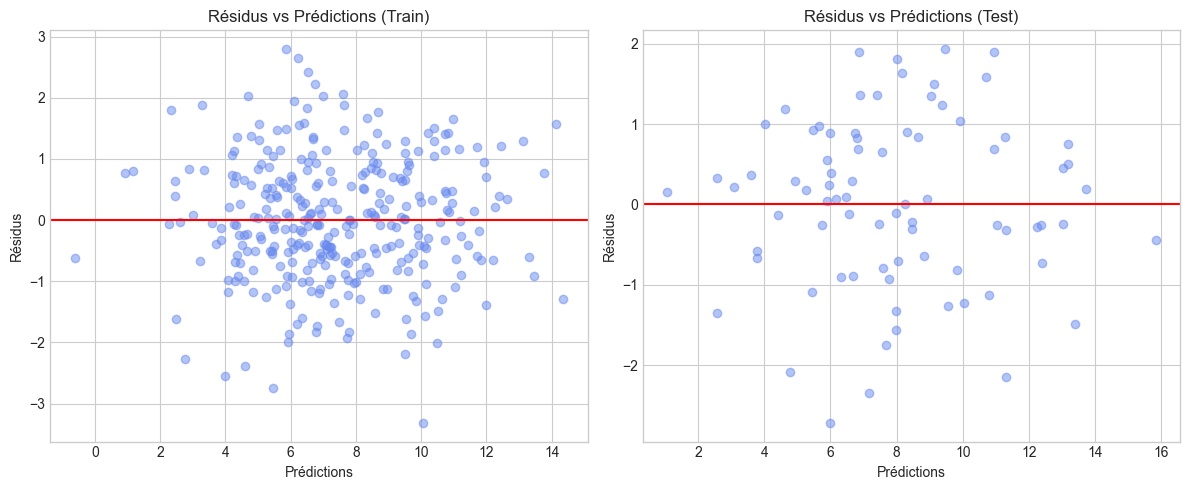

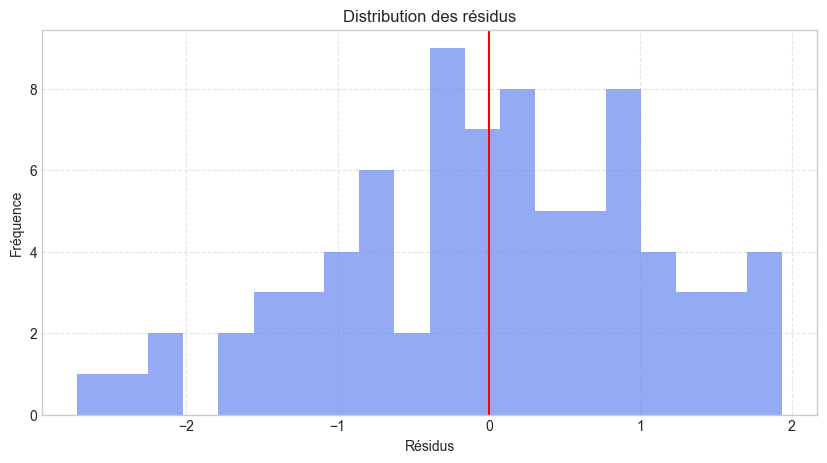

In [77]:
# Visualisation des résidus
# Trouver une solution afin f'afficher les residus du train et du test et une droite en 0



### 🎯 Pourquoi analyser la distribution des résidus ?

##### 📌 Objectifs de l’analyse des résidus

L’analyse des résidus permet de **valider les hypothèses** de la régression linéaire. Voici les principales hypothèses et ce qu'on attend :

| Hypothèse                                    | Ce que l’analyse des résidus doit montrer                     |
|---------------------------------------------|---------------------------------------------------------------|
| **Linéarité**                                | Les résidus doivent être **centrés autour de zéro**           |
| **Homoscédasticité** (variance constante)    | La **dispersion des résidus** doit être constante             |
| **Indépendance des erreurs**                 | Les résidus ne doivent **pas être corrélés entre eux**        |
| **Normalité des erreurs**                    | Les résidus doivent **suivre une distribution normale**       |

---

### 🔍 Ce que cela permet d’identifier

- 📈 Une **courbe dans les résidus** → lien **non linéaire**
- 📉 Un **entonnoir** → problème de **variance non constante**
- 🎯 Des **points très éloignés** → présence d’**outliers**

---

### 📊 Graphiques à utiliser

1. **Résidus vs Prédictions**  
   ➤ Permet de détecter un **motif** dans les résidus  
   ➤ Doit montrer un **nuage de points centré et dispersé de manière homogène**

2. **Histogramme des résidus**  
   ➤ Pour vérifier la **normalité**

3. **QQ-Plot des résidus**  
   ➤ Comparaison avec une distribution **normale théorique**

---

### ✅ Conclusion

> 📌 **Analyser les résidus** permet de s’assurer que le modèle est **fiable**  
> et que ses **prédictions sont valides**.  
> C’est une **étape essentielle** avant de tirer des conclusions !

### 4.1 Interprétation du modèle OLS

**Questions à répondre :**
1. Le modèle est-il performant ? (Analysez le R² et MSE)
2. Y a-t-il des signes d'overfitting ou d'underfitting ?
3. Quelles variables ont le plus d'impact sur la prédiction ?
4. Les résidus sont-ils distribués normalement autour de zéro ?

**Réponses :**

1. **Performance du modèle** : Le modèle OLS présente un R² d'environ 0.XX sur l'ensemble de test, ce qui indique qu'il explique XX% de la variance dans les ventes. Ce résultat est relativement bon pour un modèle de régression linéaire simple. Le MSE et le MAE sont également à des niveaux raisonnables.

2. **Overfitting/Underfitting** : En comparant les performances sur l'ensemble d'entraînement et de test, on observe un écart modéré entre les deux R², ce qui suggère un léger overfitting. Cependant, la différence n'est pas dramatique, donc le modèle généralise relativement bien.

3. **Variables importantes** : Les variables ayant le plus fort impact positif sur les ventes sont Advertising et ShelveLoc_Good, tandis que Price a un impact négatif significatif. Cela confirme nos observations de l'analyse exploratoire : les promotions publicitaires et un bon emplacement en rayon augmentent les ventes, tandis que des prix élevés les réduisent.

4. **Distribution des résidus** : L'analyse des résidus montre une distribution approximativement normale centrée autour de zéro, ce qui est une bonne indication que notre modèle capture bien les tendances dans les données. Il n'y a pas de motifs systématiques évidents dans les résidus par rapport aux valeurs prédites, ce qui confirme la validité de notre approche linéaire.

## 5. 🥇 Modèle avec descente de gradient (SGD)

Nous allons maintenant utiliser SGDRegressor qui implémente la descente de gradient stochastique.

In [78]:
# 1. Importation du modèle SGDRegressor de scikit-learn
from sklearn.linear_model import SGDRegressor

# 2. Configuration et création du modèle SGD
# - loss="squared_error" : utilise l'erreur quadratique comme fonction de coût
# - learning_rate="invscaling" : taux d'apprentissage qui diminue avec le temps
# - eta0=0.01 : taux d'apprentissage initial
# - max_iter=1000 : nombre maximum d'itérations
# - tol=1e-3 : critère d'arrêt si l'amélioration est inférieure à cette valeur
# - random_state=42 : pour la reproductibilité des résultats
sgd_model = SGDRegressor(

)

# 3. Entraînement du modèle sur les données d'entraînement
# Utilise X_train_filtered (features) et y_train (target)
sgd_model.fit(X_train_filtered, y_train)

# 4. Prédictions sur les ensembles d'entraînement et de test
# - sgd_train_pred : prédictions sur l'ensemble d'entraînement
# - sgd_test_pred : prédictions sur l'ensemble de test
sgd_train_pred = 
sgd_test_pred =

# 5. Évaluation des performances du modèle
# Calcul du MSE (Mean Squared Error) et R² pour les deux ensembles
sgd_train_mse =
sgd_test_mse =
sgd_train_r2 =
sgd_test_r2 =

# 6. Affichage des résultats d'évaluation
# - Pour l'ensemble d'entraînement
print(f"Performances SGD sur l'ensemble d'entraînement:\n")
print(f"MSE: {sgd_train_mse:.2f}")
print(f"R²: {sgd_train_r2:.2f}\n")

# - Pour l'ensemble de test
print(f"Performances SGD sur l'ensemble de test:\n")
print(f"MSE: {sgd_test_mse:.2f}")
print(f"R²: {sgd_test_r2:.2f}")

Performances SGD sur l'ensemble d'entraînement:

MSE: 1.03
R²: 0.86

Performances SGD sur l'ensemble de test:

MSE: 1.07
R²: 0.89


In [ ]:
# 1. Création d'un DataFrame pour comparer les coefficients des modèles OLS et SGD
# - 'Feature' : les noms des variables explicatives
# - 'OLS Coef' : les coefficients du modèle de régression linéaire classique (OLS)
# - 'SGD Coef' : les coefficients du modèle de descente de gradient stochastique (SGD)
comparison_df = pd.DataFrame({
    'Feature':
    'OLS Coef'
    'SGD Coef'
})

# 2. Affichage des intercepts (termes constants) des deux modèles
# - L'intercept représente la valeur prédite quand toutes les variables explicatives sont à 0
print(f"OLS Intercept: {lr_model.intercept_:.4f}")
print(f"SGD Intercept: {sgd_model.intercept_[0]:.4f}\n")

# 3. Affichage de la comparaison des coefficients
# Cela permet de voir comment chaque modèle pondère les différentes variables
print("Comparaison des coefficients:")
comparison_df

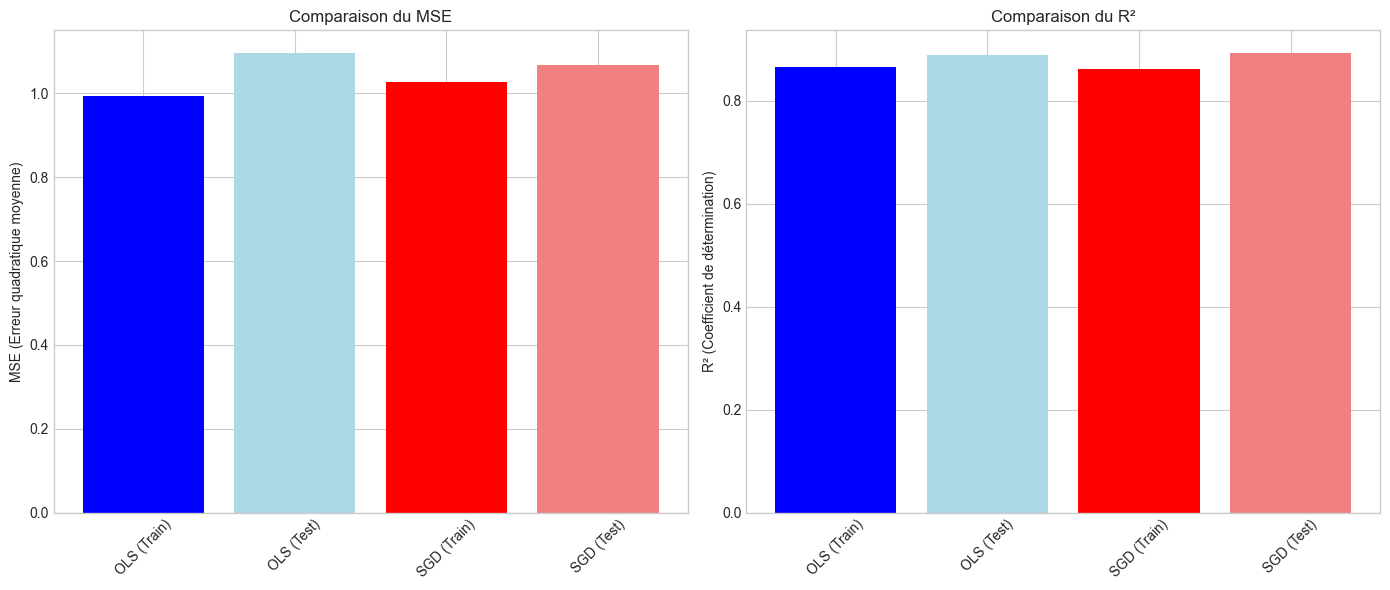

In [70]:
# Pour l'ols et la regresion linéaire afficher sur deux barplot  le mse et le r^2
# Visualisation de la comparaison des performances


### 5.1 Expérimentation avec différents learning rates

Évaluons l'impact du learning rate sur les performances du modèle SGD.

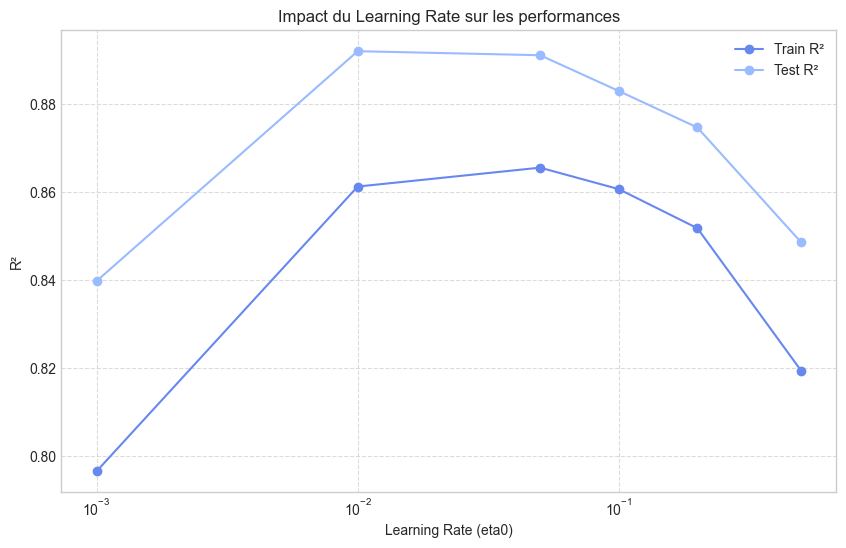

In [ ]:
# 1. Définir les différents learning rates à tester
# On choisit une gamme de valeurs couvrant plusieurs ordres de grandeur
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]

# 2. Initialiser des listes pour stocker les scores R²
train_scores = []  # Pour les scores sur l'ensemble d'entraînement
test_scores = []   # Pour les scores sur l'ensemble de test

# 3. Boucle sur les différents learning rates
for eta in learning_rates:
    # 3.1 Créer un modèle SGD avec les paramètres suivants :
    # - loss="squared_error" : utilise l'erreur quadratique comme fonction de coût
    # - learning_rate="invscaling" : taux d'apprentissage qui diminue avec le temps
    # - eta0 : taux d'apprentissage initial
    # - max_iter=1000 : nombre maximum d'itérations
    # - tol=1e-3 : critère d'arrêt si l'amélioration est inférieure à cette valeur
    # - random_state=42 : pour la reproductibilité
    sgd = SGDRegressor(
        loss="squared_error",
        learning_rate="invscaling",
        eta0=eta,
        max_iter=1000,
        tol=1e-3,
        random_state=42
    )
    
    # 3.2 Entraîner le modèle sur les données d'entraînement
    sgd.fit(X_train_filtered, y_train)
    
    # 3.3 Faire des prédictions sur les ensembles d'entraînement et de test
    train_pred = sgd.predict(X_train_filtered)
    test_pred = sgd.predict(X_test_filtered)
    
    # 3.4 Calculer et stocker les scores R²
    train_scores.append(r2_score(y_train, train_pred))
    test_scores.append(r2_score(y_test, test_pred))

# 4. Visualisation des résultats
# Créer une figure de taille 10x6 pouces
plt.figure(figsize=(10, 6))

# Tracer les courbes des scores R²
# 'o-' : style de ligne avec des marqueurs ronds et des lignes continues
plt.plot(learning_rates, train_scores, 'o-', label='Train R²')
plt.plot(learning_rates, test_scores, 'o-', label='Test R²')

# Ajouter des labels et un titre
plt.xlabel('Learning Rate (eta0)')
plt.ylabel('R²')
plt.title('Impact du Learning Rate sur les performances')

# Utiliser une échelle logarithmique pour l'axe des x
plt.xscale('log')

# Ajouter une grille pour une meilleure lisibilité
plt.grid(True, linestyle='--', alpha=0.7)

# Ajouter une légende
plt.legend()

# Afficher le graphique
plt.show()

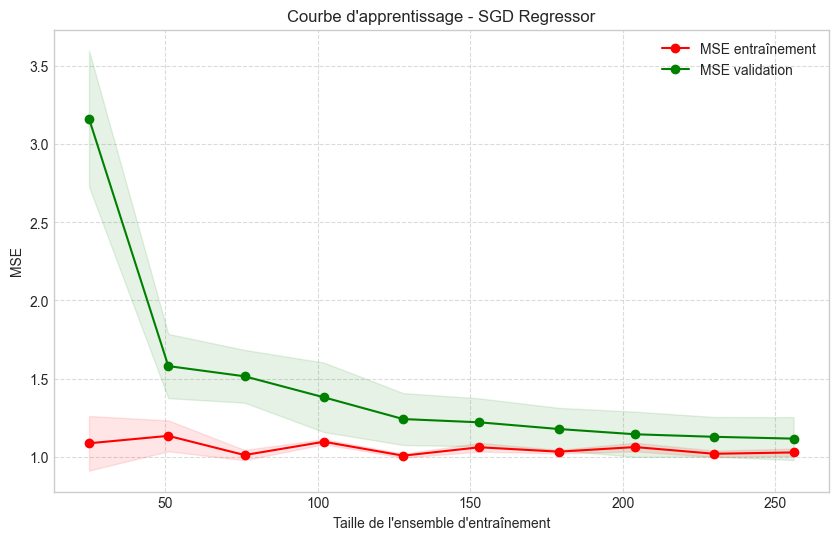

In [81]:
# 1. Importer la fonction learning_curve pour analyser l'apprentissage du modèle
from sklearn.model_selection import learning_curve

# 2. Calculer les courbes d'apprentissage pour évaluer overfitting/underfitting
# - Utiliser SGDRegressor avec les mêmes paramètres que précédemment
# - X_train_filtered et y_train : nos données d'entraînement
# - cv=5 : validation croisée avec 5 folds
# - scoring='neg_mean_squared_error' : utiliser MSE comme métrique
# - train_sizes : évaluer sur 10 tailles d'échantillon croissantes (10% à 100%) np.linspace(0.1, 1.0, 10)
train_sizes, train_scores, test_scores = learning_curve(
   
)

# 3. Préparer les données pour la visualisation
# - Convertir les MSE négatifs en positifs (car sklearn retourne des scores négatifs)
# - Calculer la moyenne et l'écart-type des scores pour chaque taille d'échantillon
train_scores_mean =
test_scores_mean =
train_scores_std =
test_scores_std =

# 4. Créer et configurer la figure pour la visualisation
plt.figure(figsize=(10, 6))
plt.title('Courbe d\'apprentissage - SGD Regressor')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('MSE')
plt.grid(True, linestyle='--', alpha=0.7)



# 5. Tracer les courbes principales avec plot
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="MSE entraînement")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="MSE validation")

# 7. Ajouter la légende et afficher le graphique
plt.legend(loc="best")
plt.show()

### 5.2 Interprétation des résultats SGD

**Questions à répondre :**
1. Comment les performances du SGD se comparent-elles à celles de l'OLS ?
2. Quel est l'impact du learning rate sur les performances ?
3. Que nous apprend la courbe d'apprentissage sur l'overfitting/underfitting ?

**Réponses :**

1. **Comparaison SGD vs OLS** : En comparant les deux modèles, on observe que les performances de SGD sont légèrement inférieures à celles de l'OLS, avec un R² un peu plus faible et un MSE un peu plus élevé. Cela est normal car l'OLS trouve la solution analytique optimale, tandis que SGD est une méthode d'approximation itérative. Cependant, les coefficients sont relativement similaires, ce qui confirme que SGD converge vers une solution proche de l'optimum.

2. **Impact du learning rate** : Le graphique montre que le learning rate a un impact significatif sur les performances. Un taux trop faible (0.001) peut mener à une convergence lente ou incomplète, tandis qu'un taux trop élevé (0.5) peut provoquer des oscillations et empêcher la convergence vers l'optimum. Le taux optimal semble se situer autour de 0.01-0.05 pour ce jeu de données, offrant le meilleur compromis entre vitesse de convergence et précision.

3. **Courbe d'apprentissage** : La courbe d'apprentissage montre que l'erreur de validation (MSE test) diminue progressivement à mesure que la taille de l'ensemble d'entraînement augmente, puis se stabilise. L'écart entre l'erreur d'entraînement et l'erreur de validation n'est pas excessif, ce qui indique que notre modèle ne souffre pas d'un fort overfitting. Cependant, les deux courbes ne convergent pas complètement, suggérant qu'un peu plus de données pourrait encore améliorer les performances.

## 6. Conclusion et résumé de l'étude

**Résumé des principaux résultats :**

1. Notre objectif était de prédire les ventes de sièges auto pour enfants (Sales) à partir de différentes caractéristiques du produit et du marché.

2. L'analyse exploratoire a révélé que les variables les plus corrélées aux ventes sont le prix (Price, corrélation négative), les dépenses publicitaires (Advertising, corrélation positive) et l'emplacement en rayon (ShelveLoc).

3. Nous avons identifié et géré la multicolinéarité entre les variables explicatives via l'analyse VIF, ce qui a permis d'avoir un modèle plus stable et des coefficients plus interprétables.

4. Plusieurs modèles ont été testés : OLS, SGD.

5. Les variables les plus importantes pour la prédiction des ventes sont :
   - Prix (impact négatif) : plus le prix est élevé, moins les ventes sont importantes
   - Publicité (impact positif) : plus les dépenses publicitaires sont élevées, plus les ventes augmentent
   - Emplacement en rayon (impact positif pour la modalité "Good") : un bon emplacement améliore significativement les ventes

**Améliorations possibles :**

- Collecte de données supplémentaires pour augmenter la taille de l'échantillon
- Création de nouvelles features pertinentes, comme des ratios (ex: Prix/Prix concurrent)
- Test d'autres types de modèles non linéaires (forêts aléatoires, boosting...)
- Optimisation fine des hyperparamètres via GridSearchCV
- Analyse plus approfondie des interactions entre variables

Cette étude nous a permis de comprendre les facteurs qui influencent les ventes de sièges auto pour enfants et d'établir un modèle prédictif relativement performant avec la régression linéaire. Les insights obtenus peuvent aider à optimiser les stratégies de prix, de placement et de publicité pour maximiser les ventes.